## 02 - Visualizing the k=8..20 Large-k Sweep (344-gene Stage-0 List, n=182)

### Aim
* Visualize the two inputs/outputs behind `large_k_EDA/run_large_k_sweep.sh` - the XDec "with refs" Stage 1/2
  reruns at `k=8..20` on the full 182-sample TCGA-PAAD cohort using this project's own 344-gene Stage-0
  probe list (not the paper's 282-gene Table S3 list used in `paper_duplication/02_visualization.ipynb`):
  (1) the Peng et al. reference's own expression for that probe list (computed once, independent of k),
  (2) for every k, the gene-level correlation between the reference cells and that k's estimated profiles.
  Both figures sort their reference axis (cells in Figure 1, pseudo-bulks in Figure 2) into the same fixed
  **biological-compartment** order used throughout this project - pancreatic epithelium (acinar, ductal,
  enteroendocrine) -> stroma (stellate, fibroblast, endothelial, neural) -> immune (T cell, B lineage,
  myeloid) - rather than alphabetically or by clustering, so related cell types sit next to each other.
  Figure 1 clusters genes (rows); Figure 2 keeps profiles in fixed `Profile_1..k` order per k.

### Input
* `data/deconvolution/xdec/stage0/selected_probes.txt` - the project's 344-gene Stage-0 probe list.
* `data/deconvolution/xdec/{refs.tsv, ref_metadata.tsv}` - Peng et al. 2019 single-cell reference (notebook 04).
* `data/deconvolution/xdec/stage1_with_refs_k{8..20}/cell_type_profiles.tsv` - the 13 large-k sweep runs
  produced by `large_k_EDA/run_large_k_sweep.sh`.

### Output
* `large_k_EDA/figures/fig_reference_expression_clustermap.png` - z-scored heatmap of reference single-cell
  expression over the 344-gene probe list, genes clustered, cells sorted into fixed biological-compartment
  cell-type blocks. Independent of k.
* `large_k_EDA/figures/fig_profile_reference_correlation_clustermap_k{8..20}.png` - one heatmap per k of
  Spearman correlation between that k's estimated profiles (fixed `Profile_1..k` order) and reference
  pseudo-bulks, pseudo-bulks sorted into the same fixed biological-compartment cell-type blocks.

### Steps
1. Restrict the 344-gene probe list to genes present in both `refs.tsv` and every k's `cell_type_profiles.tsv`.
2. Figure 1: z-score the reference's single-cell expression over those genes and plot a gene-clustered,
   compartment-sorted clustermap.
3. Build one (patient, cell type) pseudo-bulk reference per group from the same gene set (independent of k).
4. Figure 2: for each k in 8..20, Spearman-correlate that k's profiles against every pseudo-bulk and plot a
   compartment-sorted clustermap, looping over all 13 sweep results.

### Result
* See the per-k clustermaps and gene-count diagnostics below.

### Conclusion
* See the per-k clustermaps below for how profile-to-cell-type correspondence changes as k increases from 8
  to 20.


In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# This notebook lives in progress/large_k_EDA/; Jupyter starts the kernel with
# cwd = the notebook's own folder, and every "data/..." path below is relative to progress/.
if os.path.basename(os.getcwd()) == "large_k_EDA":
    os.chdir("..")

XDEC_DIR = "data/deconvolution/xdec"
FIG_DIR = os.path.join("large_k_EDA", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

K_VALUES = list(range(8, 21))

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

# Single-hue sequential blue ramp (magnitude encoding), light -> dark - matches this
# project's other publication-style figures (notebook 10, paper_duplication/02_visualization.ipynb).
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)

os.getcwd()


'/Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress'

### Step 1: restrict the 344-gene Stage-0 probe list to genes present in the reference and in every k's profiles

In [2]:
probes = [l.strip() for l in open(os.path.join(XDEC_DIR, "stage0", "selected_probes.txt")) if l.strip()]

refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)

profiles_by_k = {
    k: pd.read_csv(os.path.join(XDEC_DIR, f"stage1_with_refs_k{k}", "cell_type_profiles.tsv"), sep="\t", index_col=0)
    for k in K_VALUES
}

genes = [g for g in probes if g in refs.index and all(g in profiles_by_k[k].index for k in K_VALUES)]
print(f"{len(genes)}/{len(probes)} of the 344 Stage-0 probes present in refs.tsv and every k={K_VALUES[0]}..{K_VALUES[-1]} cell_type_profiles.tsv")

ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]

# Fixed biological-compartment order (not alphabetical) so visually/functionally related cell types sit
# next to each other: pancreatic epithelial/parenchymal, then stroma, then immune - matches
# paper_duplication/02_visualization.ipynb and notebook 11.
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",   # pancreatic epithelium
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",  # stroma
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",                     # immune
]
assert set(cell_type_order) == set(ref_cell_types.unique()), "cell_type_order must cover every reference cell type"
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", n_colors=len(cell_type_order))))


341/344 of the 344 Stage-0 probes present in refs.tsv and every k=8..20 cell_type_profiles.tsv


### Step 2: Figure 1 - reference expression over the shared gene list, z-scored, columns sorted by biological compartment

Independent of k - the 344-gene probe list and the reference are the same across every k=8..20 run. Each
gene (row) is z-scored across all 2,748 reference single cells before plotting (standard for marker-gene
heatmaps, matching notebook 11's method). Genes (rows) are hierarchically clustered purely for visual
grouping of co-expressed genes. Cells (columns) are sorted into fixed blocks by `cell_type_order` - never
reordered by clustering.

341/341 genes kept after dropping zero-variance rows


/Users/liruixi/.pixi/envs/python/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


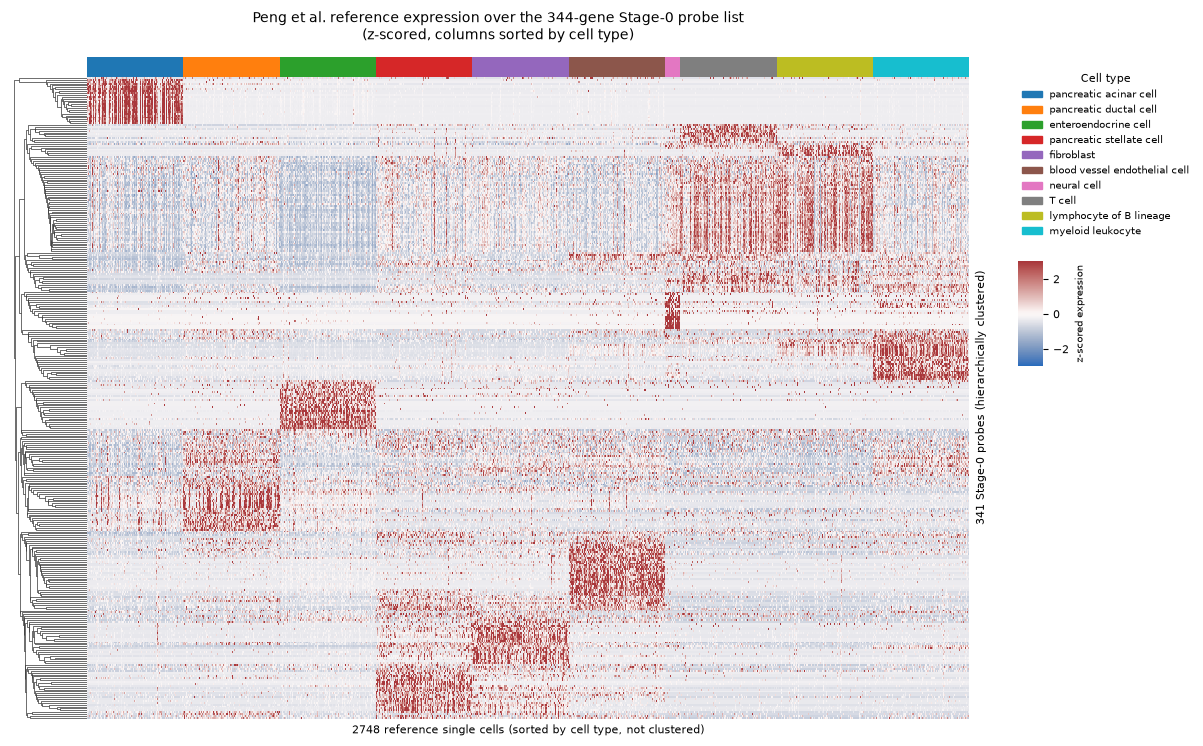

In [3]:
expr = refs.loc[genes]
zscored = expr.sub(expr.mean(axis=1), axis=0).div(expr.std(axis=1).replace(0, np.nan), axis=0)
zscored = zscored.dropna(how="any")
print(f"{zscored.shape[0]}/{len(genes)} genes kept after dropping zero-variance rows")

col_types = pd.Categorical(ref_cell_types.loc[zscored.columns], categories=cell_type_order, ordered=True)
col_order = pd.Series(col_types, index=zscored.columns).sort_values(kind="stable").index
zscored = zscored[col_order]

col_colors = ref_cell_types.loc[zscored.columns].map(cell_palette)
col_colors.name = "Cell type"

g1 = sns.clustermap(
    zscored, row_cluster=True, col_cluster=False,
    col_colors=col_colors.values,
    cmap="vlag", vmin=-3, vmax=3, center=0,
    xticklabels=False, yticklabels=False,
    figsize=(10, 7), cbar_kws={"label": "z-scored expression"},
    dendrogram_ratio=(0.08, 0.02),
)
g1.ax_heatmap.set_xlabel(f"{zscored.shape[1]} reference single cells (sorted by cell type, not clustered)")
g1.ax_heatmap.set_ylabel(f"{zscored.shape[0]} Stage-0 probes (hierarchically clustered)")
handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend1 = g1.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
g1.fig.suptitle("Peng et al. reference expression over the 344-gene Stage-0 probe list\n(z-scored, columns sorted by cell type)",
                 y=1.03, fontsize=10)

g1.cax.yaxis.label.set_fontsize(7)
g1.fig.canvas.draw()
legend_bbox = legend1.get_window_extent(g1.fig.canvas.get_renderer()).transformed(g1.fig.transFigure.inverted())
cbar_width, cbar_height, gap = 0.025, 0.15, 0.03
g1.cax.set_position([legend_bbox.x0, legend_bbox.y0 - cbar_height - gap, cbar_width, cbar_height])

g1.savefig(os.path.join(FIG_DIR, "fig_reference_expression_clustermap.png"), dpi=200, bbox_inches="tight")
plt.show()


### Step 3: build (patient, cell type) pseudo-bulks - independent of k

Matching the gene-level approach used elsewhere in this project (notebook 10's Figure 2A duplicate, and
`paper_duplication/02_visualization.ipynb`): single cells are averaged into one pseudo-bulk per (patient,
cell type) pair over the shared gene list. This only depends on `refs.tsv`/`ref_metadata.tsv` and the gene
list, so it is computed once and reused for every k in Figure 2.

In [4]:
ref_sub = refs.loc[genes]
patients = pd.Series(ref_sub.columns, index=ref_sub.columns).str.split("_").str[0]
group_key = patients.astype(str) + " | " + ref_cell_types.astype(str)
pseudobulk = ref_sub.T.groupby(group_key).mean().T
pb_cell_types = pd.Series({c: c.split(" | ")[1] for c in pseudobulk.columns})
print(f"{ref_sub.shape[1]} single cells -> {pseudobulk.shape[1]} (patient x cell type) pseudo-bulk references")

pb_types = pd.Categorical(pb_cell_types, categories=cell_type_order, ordered=True)
pb_col_order = pd.Series(pb_types, index=pb_cell_types.index).sort_values(kind="stable").index
pseudobulk = pseudobulk[pb_col_order]
pb_cell_types = pb_cell_types.loc[pb_col_order]

pb_col_colors = pb_cell_types.map(cell_palette)
pb_col_colors.name = "Cell type"


2748 single cells -> 270 (patient x cell type) pseudo-bulk references


### Step 4: Figure 2 - profiles vs. reference pseudo-bulks, gene-level granularity, looped over k=8..20

Each k's estimated profiles (`cell_type_profiles.tsv`) are Spearman-correlated against every pseudo-bulk
individually, restricted to the same shared gene list used in Figure 1. Pseudo-bulks (columns) are sorted
into the fixed `cell_type_order` biological-compartment blocks - never reordered by clustering; profiles
(rows) are left in fixed `Profile_1..k` order.

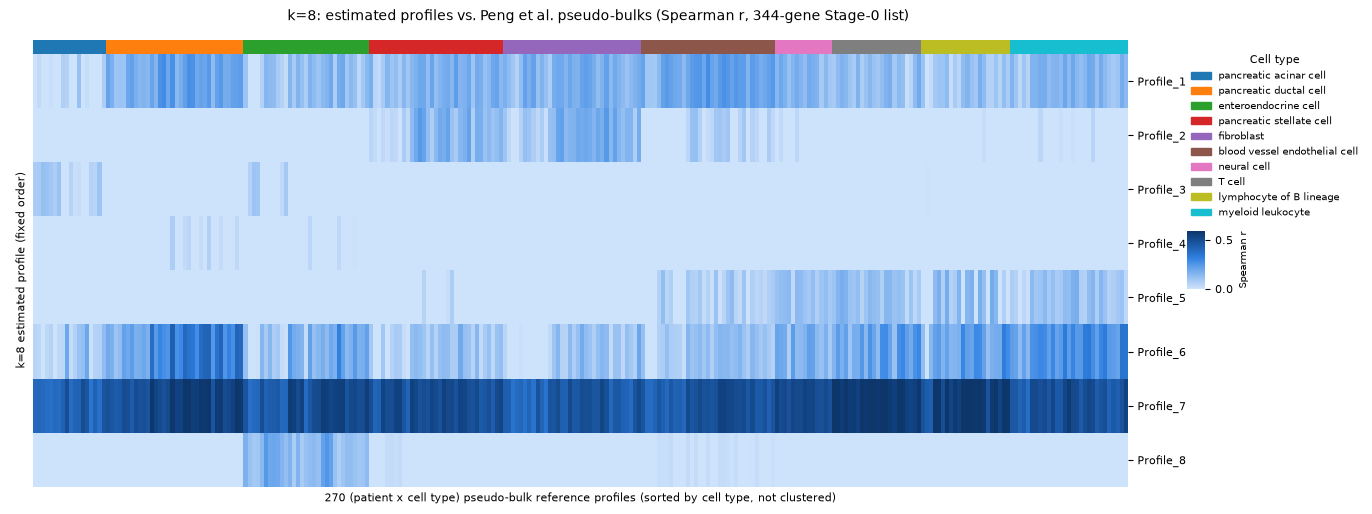

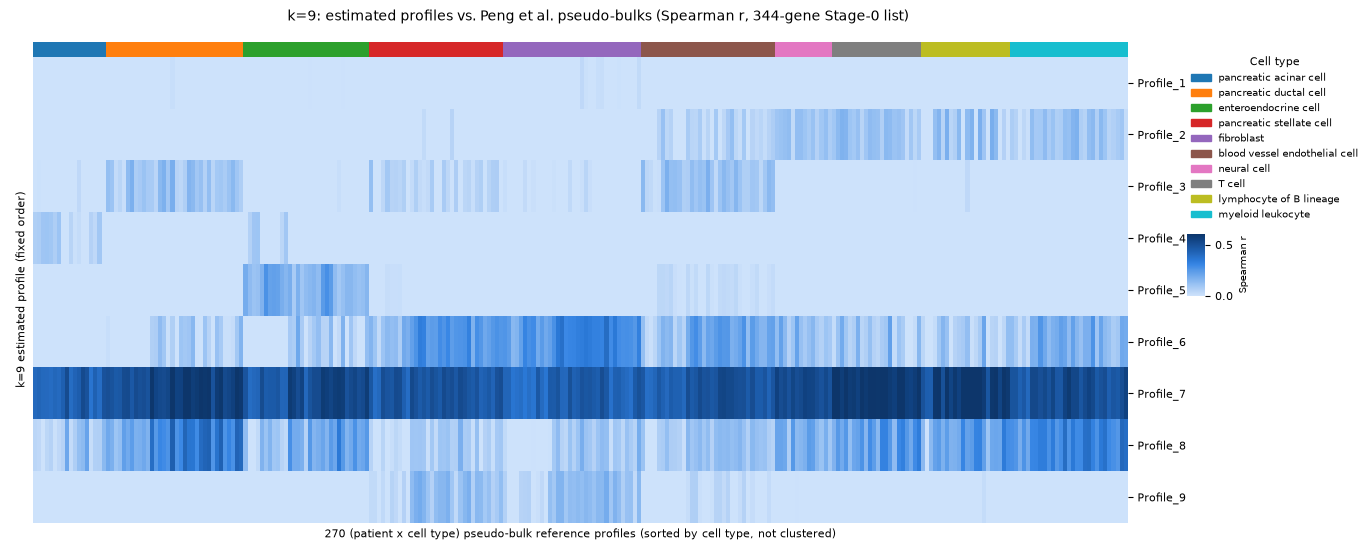

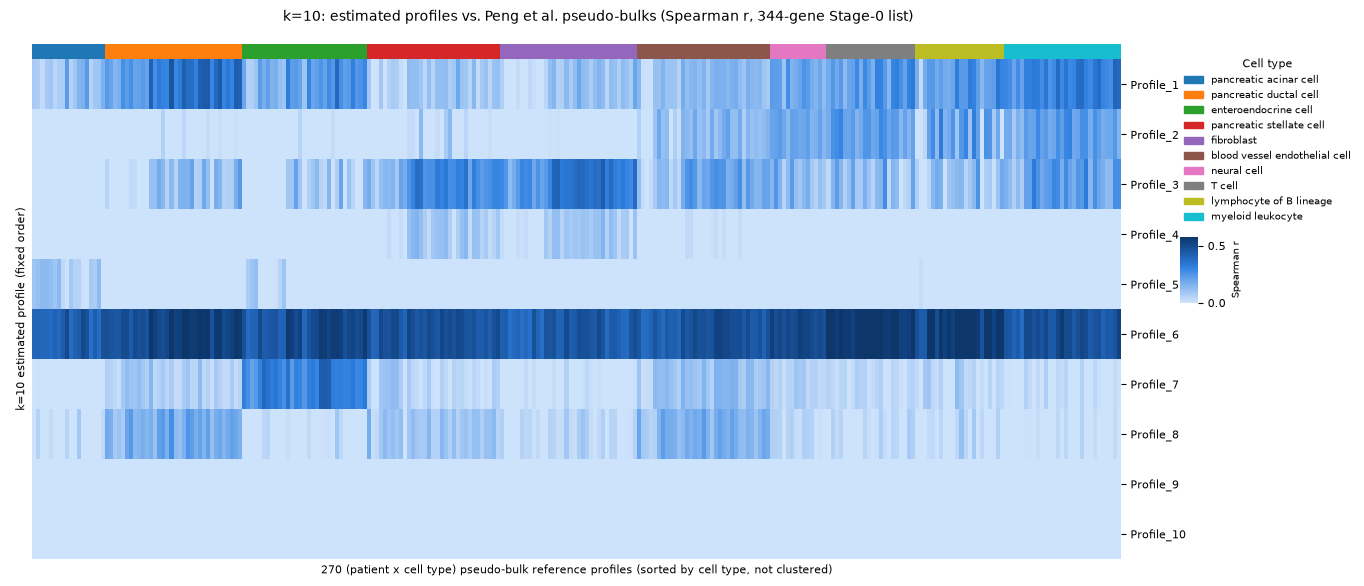

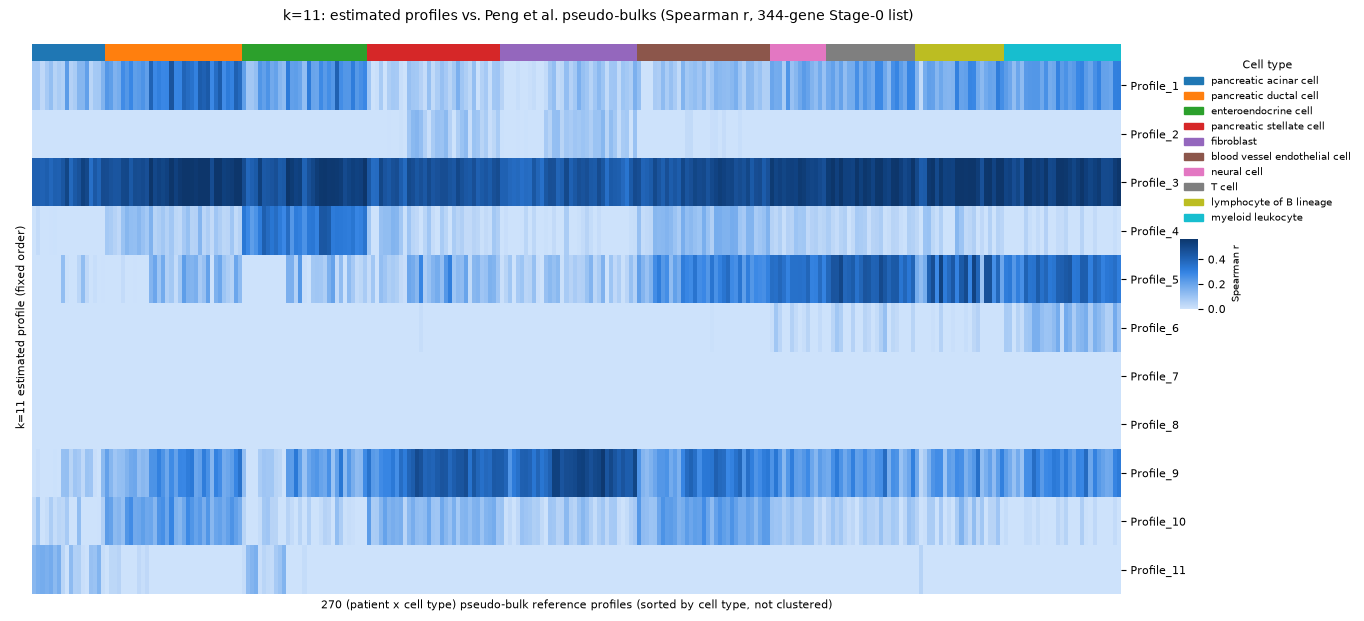

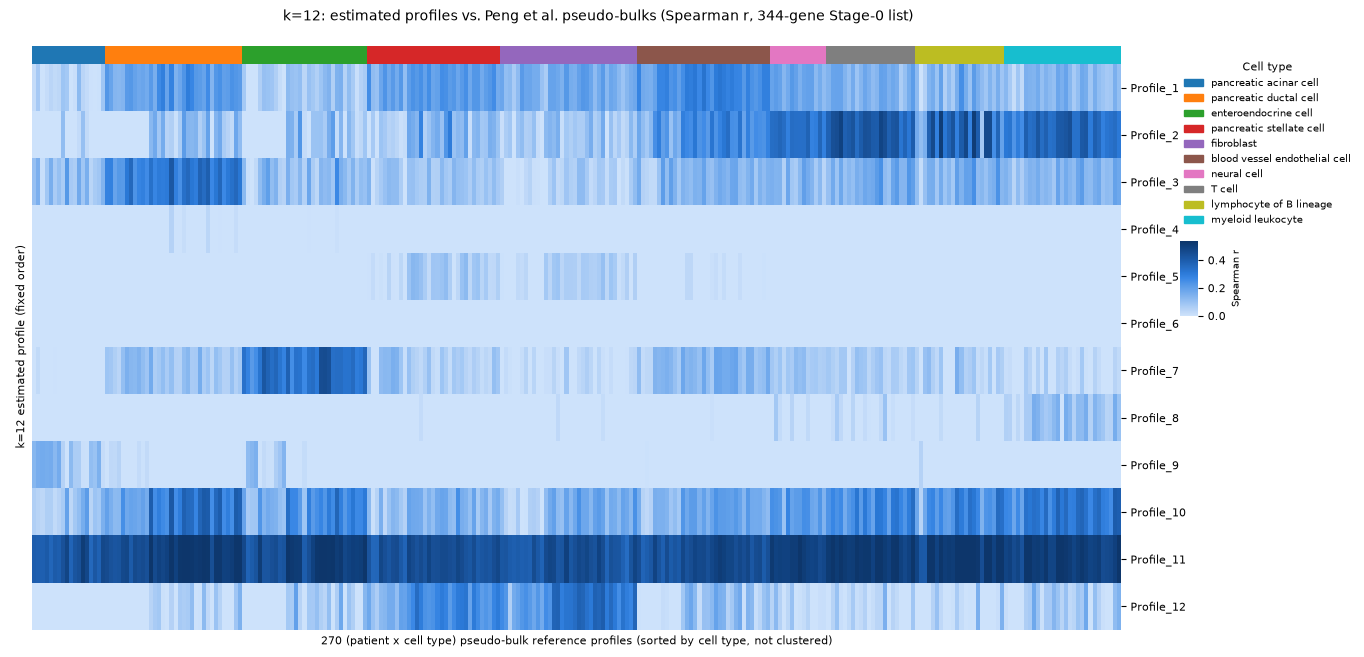

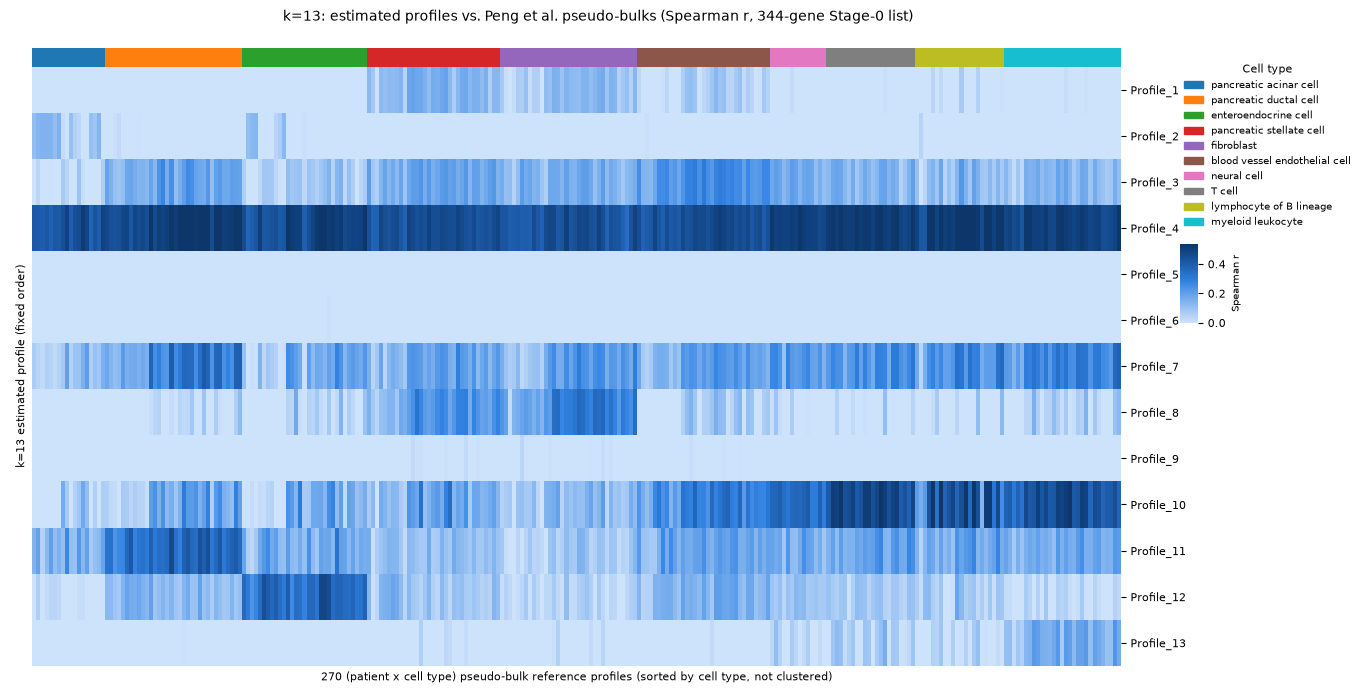

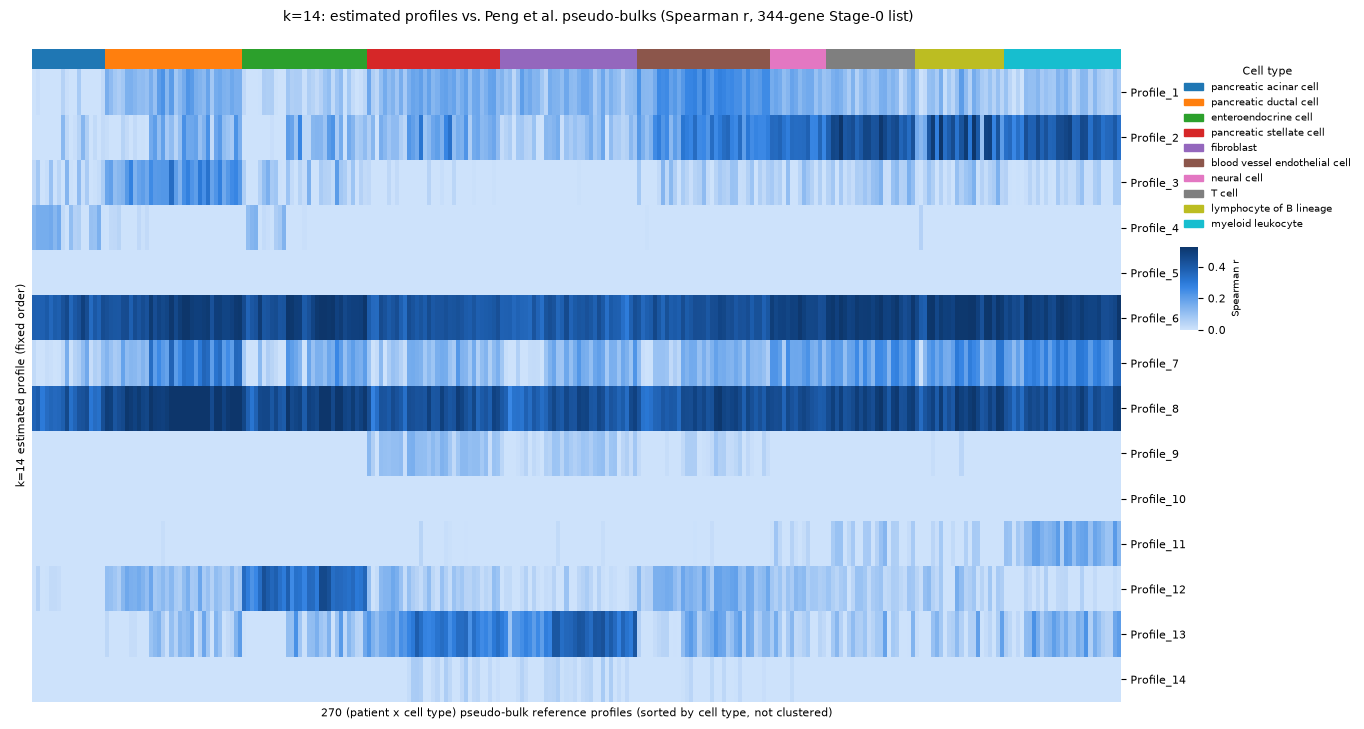

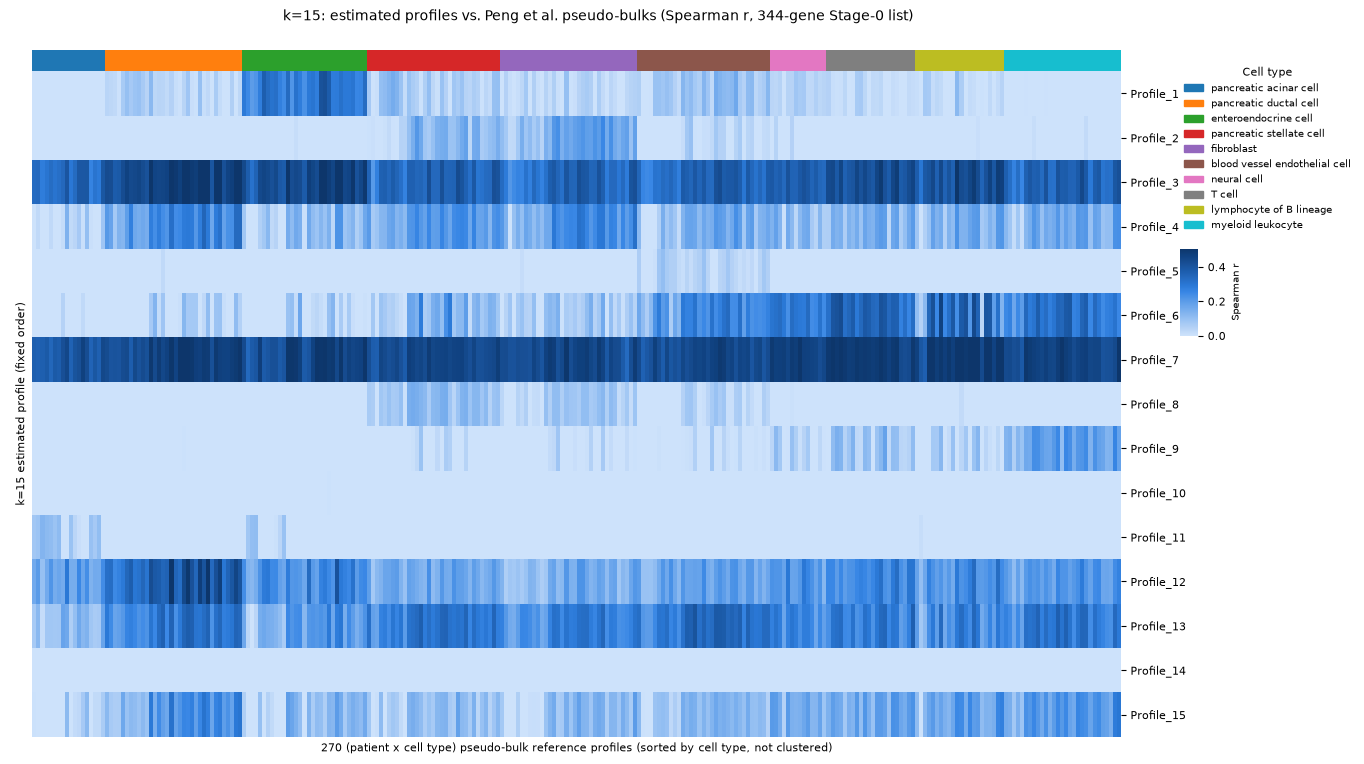

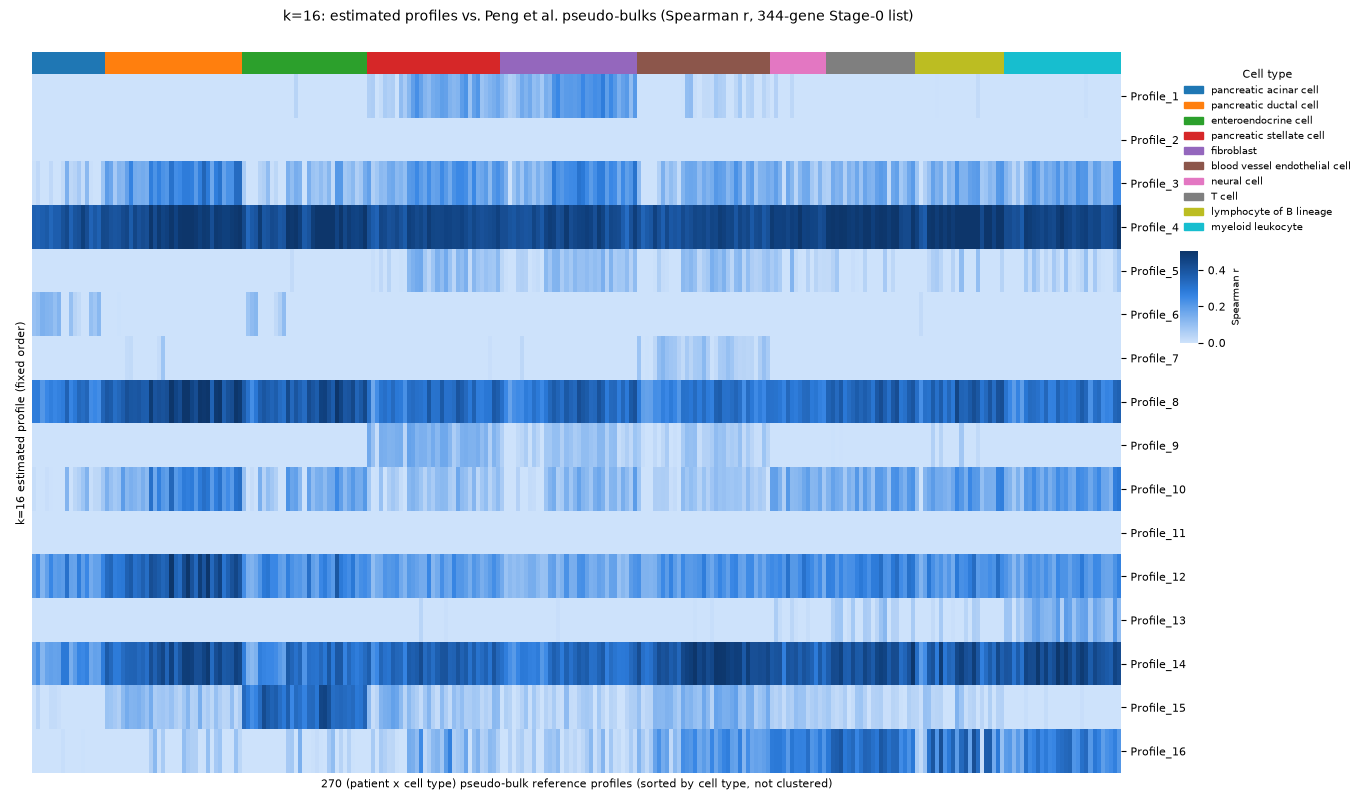

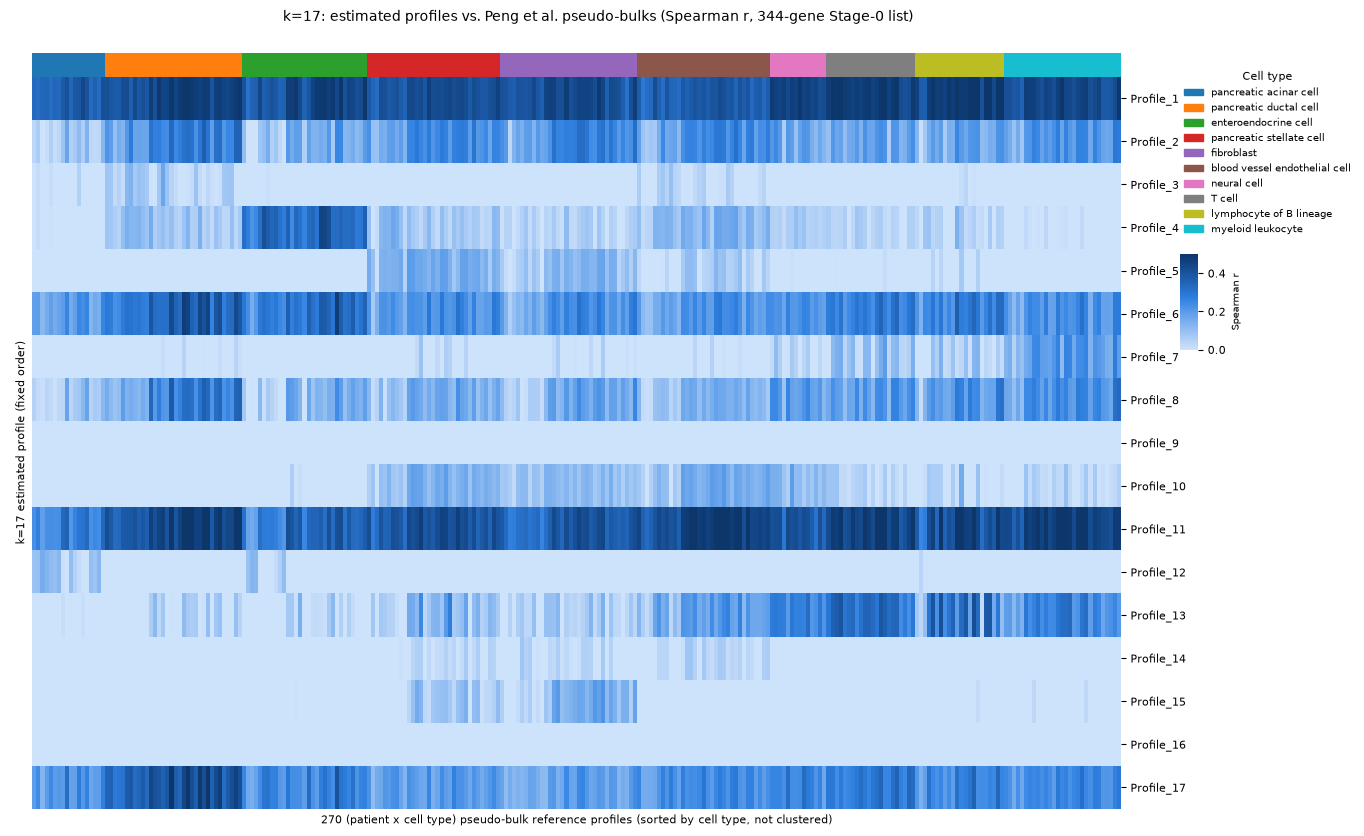

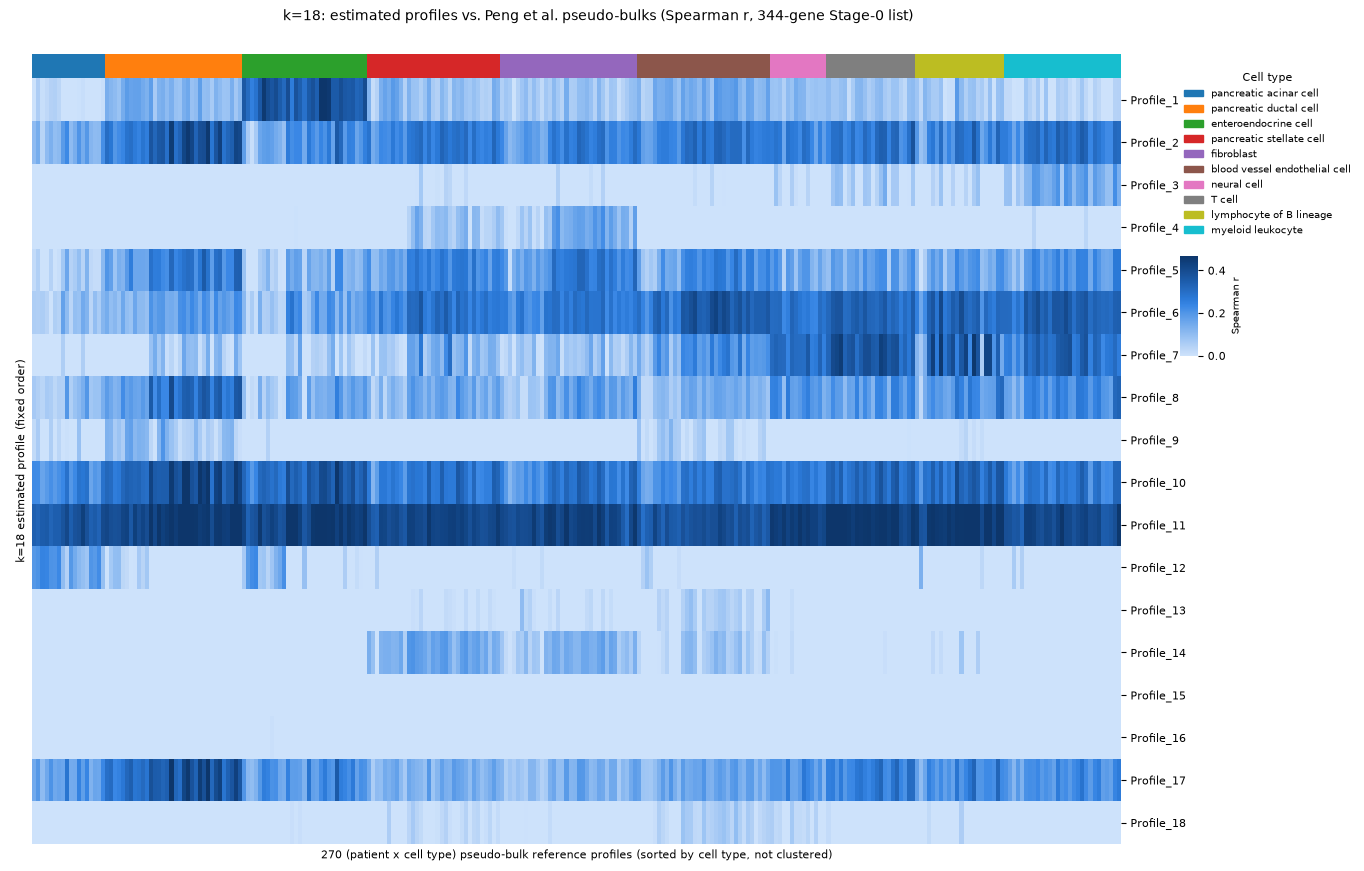

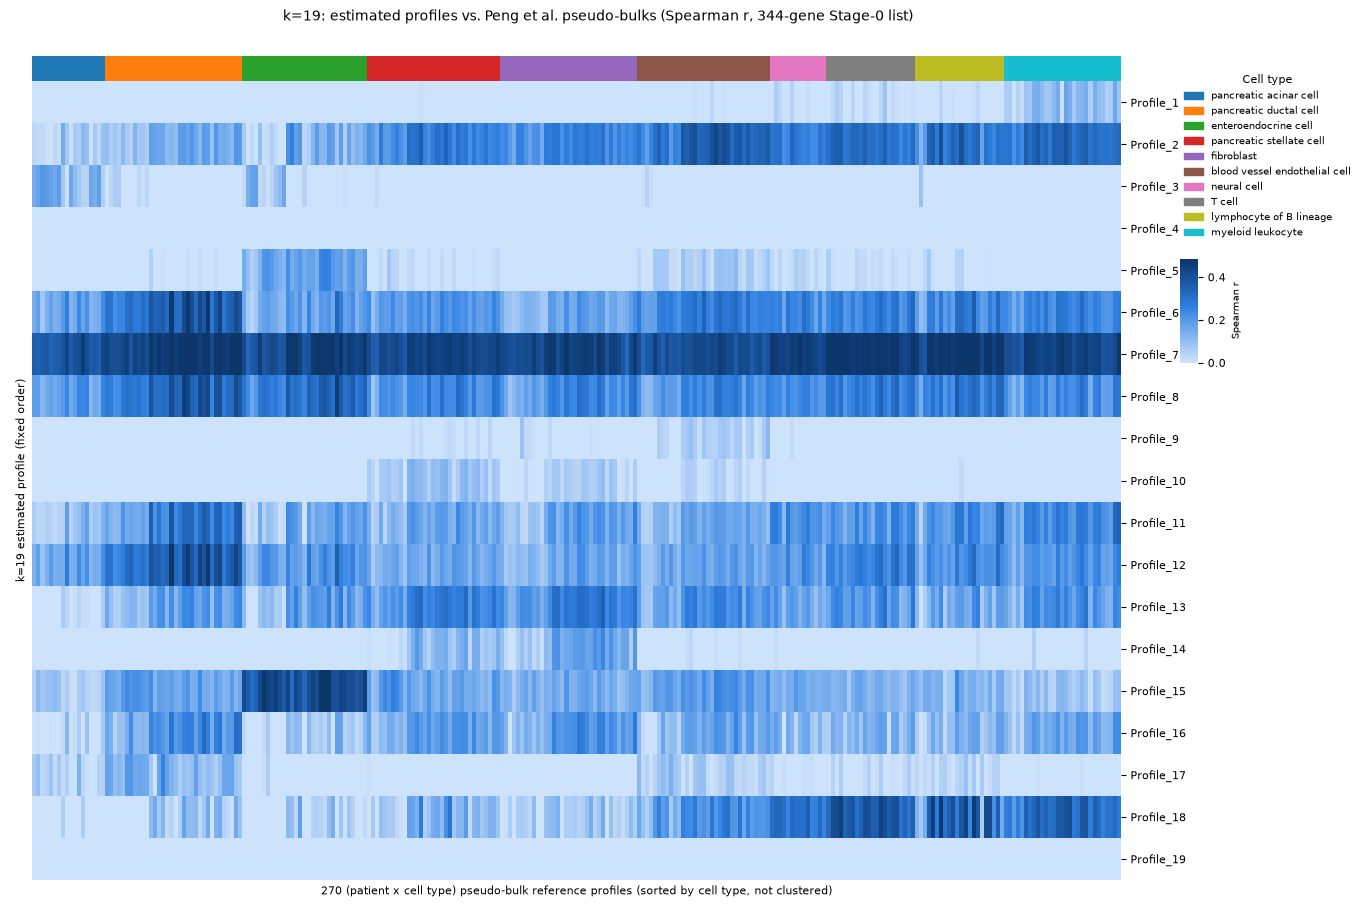

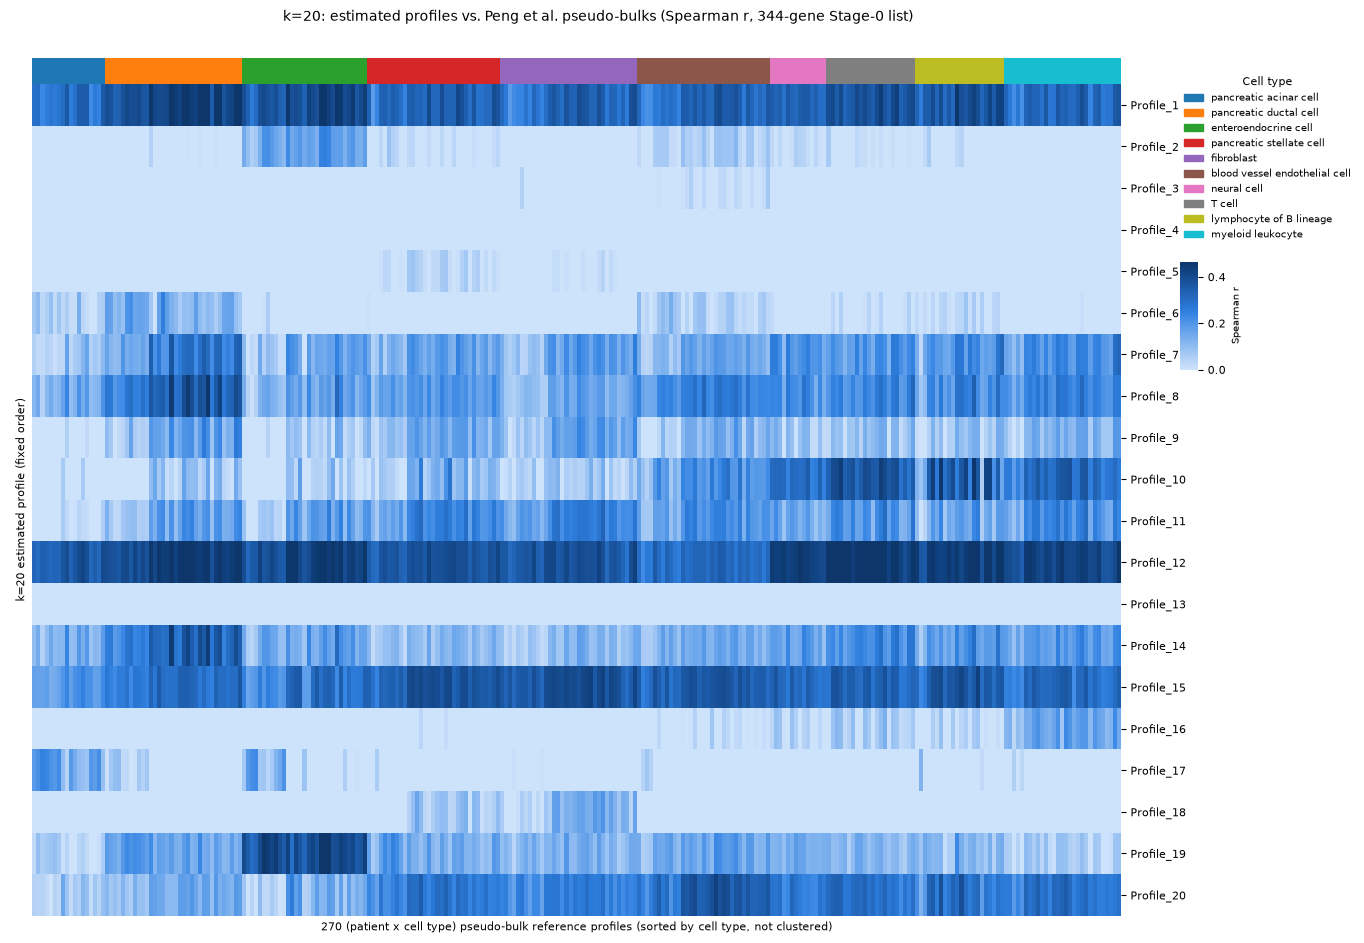

In [5]:
corr_by_k = {}

for k in K_VALUES:
    profile_order = [f"Profile_{i}" for i in range(1, k + 1)]
    combined = pd.concat([pseudobulk, profiles_by_k[k].loc[genes, profile_order]], axis=1)
    corr_full = combined.corr(method="spearman")
    corr_k = corr_full.loc[profile_order, pseudobulk.columns]
    corr_by_k[k] = corr_k

    g2 = sns.clustermap(
        corr_k, row_cluster=False, col_cluster=False,
        col_colors=pb_col_colors.values,
        cmap=seq_blue, vmin=0, vmax=float(np.percentile(corr_k.values, 99)),
        xticklabels=False, yticklabels=True,
        figsize=(12, 0.35 * k + 2), cbar_kws={"label": "Spearman r"},
        dendrogram_ratio=(0.02, 0.02),
    )
    g2.ax_heatmap.set_xlabel(f"{corr_k.shape[1]} (patient x cell type) pseudo-bulk reference profiles (sorted by cell type, not clustered)")
    g2.ax_heatmap.set_ylabel(f"k={k} estimated profile (fixed order)")
    g2.ax_heatmap.yaxis.set_label_position("left")
    g2.ax_heatmap.tick_params(axis="y", rotation=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
    legend2 = g2.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                    loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
    g2.fig.suptitle(f"k={k}: estimated profiles vs. Peng et al. pseudo-bulks (Spearman r, 344-gene Stage-0 list)",
                     y=1.02, fontsize=10)

    g2.cax.yaxis.label.set_fontsize(7)
    g2.fig.canvas.draw()
    legend_bbox = legend2.get_window_extent(g2.fig.canvas.get_renderer()).transformed(g2.fig.transFigure.inverted())
    cbar_width, cbar_height, gap = 0.015, 0.12, 0.02
    g2.cax.set_position([legend_bbox.x0, legend_bbox.y0 - cbar_height - gap, cbar_width, cbar_height])

    g2.savefig(os.path.join(FIG_DIR, f"fig_profile_reference_correlation_clustermap_k{k}.png"), dpi=200, bbox_inches="tight")
    plt.show()


### Step 5: best-matching cell type per profile, across k

For each k, the reference cell type whose pseudo-bulks have the highest mean Spearman r against each
profile - a compact readout of how cleanly each profile maps onto a single reference cell type as k grows
from 8 to 20, without having to re-read all 13 clustermaps above.

In [6]:
best_match_rows = []
for k in K_VALUES:
    corr_k = corr_by_k[k]
    mean_by_type = corr_k.T.groupby(pb_cell_types.loc[corr_k.columns]).mean().T  # profiles x cell types
    for profile in mean_by_type.index:
        best_type = mean_by_type.loc[profile].idxmax()
        best_match_rows.append({
            "k": k, "profile": profile,
            "best_matching_cell_type": best_type,
            "mean_spearman_r": mean_by_type.loc[profile, best_type],
        })

best_match = pd.DataFrame(best_match_rows)
best_match


,k,profile,best_matching_cell_type,mean_spearman_r
0,8,Profile_1,blood vessel endothelial cell,0.203352
1,8,Profile_2,fibroblast,0.128873
2,8,Profile_3,pancreatic acinar cell,0.034942
3,8,Profile_4,pancreatic ductal cell,-0.055351
4,8,Profile_5,T cell,0.108827
...,...,...,...,...
177,20,Profile_16,myeloid leukocyte,0.151580
178,20,Profile_17,pancreatic acinar cell,0.163767
179,20,Profile_18,fibroblast,0.093604
180,20,Profile_19,enteroendocrine cell,0.402350
